# K-Nearest Neighbors — Hyperparameter Tuning

Loads the shared train/val/test splits saved by `data_eda.ipynb`, vectorizes with TF-IDF (update the
config below if `bow_vs_tfidf.ipynb` found a better one than the default), then grid-searches
K-Nearest Neighbors's key hyperparameters. Every candidate combination is logged to MLflow, and the best model
gets registered.

**Note:** KNN has to compute distances to every training point at prediction time, which gets slow on high-dimensional sparse TF-IDF vectors — expect this notebook to take noticeably longer than the others. That slowness is itself a useful finding: it's part of why KNN isn't commonly used for text classification at scale.

Run `data_eda.ipynb` first — this notebook depends on the CSVs it saves.

In [9]:
# ── libraries ──
import os
import time
import pickle

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix
from sklearn.neighbors import KNeighborsClassifier
from sklearn.decomposition import TruncatedSVD

import mlflow
import mlflow.sklearn
from mlflow.tracking import MlflowClient

In [10]:
# ── config + load the shared splits ──
MODEL_NAME = "KNN"
SEED = 42

DATA_DIR = "../data/processed"
RESULTS_DIR = "results"
MODELS_DIR = "saved_models"
os.makedirs(RESULTS_DIR, exist_ok=True)
os.makedirs(MODELS_DIR, exist_ok=True)

MLFLOW_EXPERIMENT = "IndianFinSentiment_ClassicalML"
mlflow.set_tracking_uri("sqlite:///mlflow.db")
mlflow.set_experiment(MLFLOW_EXPERIMENT)

train_df = pd.read_csv(f"{DATA_DIR}/train.csv")
val_df = pd.read_csv(f"{DATA_DIR}/val.csv")
test_df = pd.read_csv(f"{DATA_DIR}/test.csv")
print(f"Train: {len(train_df)}  |  Val: {len(val_df)}  |  Test: {len(test_df)}")

Train: 7094  |  Val: 946  |  Test: 1419


## Vectorize with TF-IDF

**Update these two values** if `bow_vs_tfidf.ipynb` found a better config than this default.

In [11]:
TFIDF_MAX_FEATURES = 15_000
TFIDF_NGRAM_RANGE = (1, 2)

vectorizer = TfidfVectorizer(max_features=TFIDF_MAX_FEATURES, ngram_range=TFIDF_NGRAM_RANGE, min_df=2)
X_train = vectorizer.fit_transform(train_df["text"])
X_val = vectorizer.transform(val_df["text"])
X_test = vectorizer.transform(test_df["text"])

y_train, y_val, y_test = train_df["label_id"], val_df["label_id"], test_df["label_id"]
print(f"TF-IDF matrix shape: {X_train.shape}")

TF-IDF matrix shape: (7094, 11720)


In [12]:
def evaluate(y_true, y_pred):
    per_class = f1_score(y_true, y_pred, average=None, labels=[0, 1, 2])
    return {
        "accuracy": round(accuracy_score(y_true, y_pred), 4),
        "f1_weighted": round(f1_score(y_true, y_pred, average="weighted"), 4),
        "f1_positive": round(per_class[0], 4),
        "f1_neutral": round(per_class[1], 4),
        "f1_negative": round(per_class[2], 4),
    }


def plot_confusion_matrix(y_true, y_pred, name):
    cm = confusion_matrix(y_true, y_pred)
    cm_pct = cm.astype(float) / cm.sum(axis=1)[:, None]
    fig, ax = plt.subplots(figsize=(5, 4))
    sns.heatmap(cm_pct, annot=True, fmt=".1%", cmap="Blues",
                xticklabels=["positive", "neutral", "negative"],
                yticklabels=["positive", "neutral", "negative"], ax=ax)
    ax.set_title(f"Confusion Matrix - {name}")
    ax.set_xlabel("Predicted"); ax.set_ylabel("Actual")
    path = f"{RESULTS_DIR}/cm_{name.lower().replace(' ', '_')}.png"
    plt.savefig(path, dpi=120, bbox_inches="tight")
    plt.show()
    return path

## Broader hyperparameter search

The old version only searched `n_neighbors` (5 values) x `weights` (2 values) — 10 candidates x
3-fold CV = 30 fits. This version adds `metric` (`cosine`, `euclidean`, `manhattan`) — cosine
distance in particular usually suits high-dimensional sparse TF-IDF vectors much better than
euclidean, since it ignores document length and only compares direction — and widens the
`n_neighbors` range. Full grid (9x2x3=54 combos) is small enough to search exhaustively with
`GridSearchCV` at `cv=5` and `verbose=2`, so every fold's fit prints as it happens.

**Note on "training":** KNN has no fitting/optimization process — `.fit()` just stores the
training vectors, and all the actual work happens at prediction time (compute distance to every
stored point). There's no epoch loop possible here the way there is for the other classical
models in this project; the closest analogue is the `n_neighbors` sweep further down, which is
KNN's real complexity dial (small k = complex/overfit-prone boundary, large k = smooth/underfit-
prone boundary — the opposite direction from "more epochs").

In [13]:
model = KNeighborsClassifier(n_jobs=-1)

param_grid = {
    "n_neighbors": [3, 5, 7, 9, 11, 15, 21, 31, 51],
    "weights": ["uniform", "distance"],
    "metric": ["cosine", "euclidean", "manhattan"],
}

start = time.time()
grid_search = GridSearchCV(model, param_grid, cv=5, scoring="f1_weighted", n_jobs=-1, verbose=2)
grid_search.fit(X_train, y_train)
search_time = time.time() - start

n_combos = len(grid_search.cv_results_["params"])
print(f"\nGrid search done in {search_time:.1f}s — tried {n_combos} combinations x 5-fold CV = {n_combos * 5} fits")
print(f"Best params: {grid_search.best_params_}")
print(f"Best CV F1 (weighted): {grid_search.best_score_:.4f}")

Fitting 5 folds for each of 54 candidates, totalling 270 fits
[CV] END ......metric=cosine, n_neighbors=3, weights=uniform; total time=   1.0s
[CV] END ......metric=cosine, n_neighbors=3, weights=uniform; total time=   1.0s
[CV] END .....metric=cosine, n_neighbors=3, weights=distance; total time=   1.0s
[CV] END ......metric=cosine, n_neighbors=3, weights=uniform; total time=   1.0s
[CV] END ......metric=cosine, n_neighbors=3, weights=uniform; total time=   1.0s
[CV] END .....metric=cosine, n_neighbors=3, weights=distance; total time=   1.0s
[CV] END ......metric=cosine, n_neighbors=3, weights=uniform; total time=   1.0s
[CV] END .....metric=cosine, n_neighbors=3, weights=distance; total time=   1.1s
[CV] END .....metric=cosine, n_neighbors=3, weights=distance; total time=   0.6s
[CV] END .....metric=cosine, n_neighbors=3, weights=distance; total time=   0.6s
[CV] END ......metric=cosine, n_neighbors=5, weights=uniform; total time=   0.8s
[CV] END .....metric=cosine, n_neighbors=5, wei

## Log every candidate combination to MLflow

In [14]:
for params, mean_score, std_score in zip(
    grid_search.cv_results_["params"],
    grid_search.cv_results_["mean_test_score"],
    grid_search.cv_results_["std_test_score"],
):
    run_name = f"{MODEL_NAME}_" + "_".join(f"{k}={v}" for k, v in params.items())
    with mlflow.start_run(run_name=run_name):
        mlflow.log_params(params)
        mlflow.log_metric("cv_f1_weighted_mean", round(float(mean_score), 4))
        mlflow.log_metric("cv_f1_weighted_std", round(float(std_score), 4))

print(f"Logged {len(grid_search.cv_results_['params'])} candidate runs to MLflow.")

Logged 54 candidate runs to MLflow.


## Overfitting check: train vs val vs test (raw TF-IDF, CV-best)

In [15]:
cv_best_model = grid_search.best_estimator_
train_metrics_cv = evaluate(y_train, cv_best_model.predict(X_train))
val_metrics_cv = evaluate(y_val, cv_best_model.predict(X_val))
test_metrics_cv = evaluate(y_test, cv_best_model.predict(X_test))

print(f"{'Split':<8} {'Accuracy':>10} {'F1 (weighted)':>14}")
for name, m in [("Train", train_metrics_cv), ("Val", val_metrics_cv), ("Test", test_metrics_cv)]:
    print(f"{name:<8} {m['accuracy']:>10.4f} {m['f1_weighted']:>14.4f}")

gap = train_metrics_cv["f1_weighted"] - val_metrics_cv["f1_weighted"]
print(f"\nTrain-Val F1 gap: {gap:.4f}")
print("(with weights='distance', train F1 is often ~1.0 by construction — every training point")
print("is its own nearest neighbor at distance 0 — so this gap is expected and not a useful")
print("overfitting signal for KNN specifically; val/test performance is what actually matters.)")

Split      Accuracy  F1 (weighted)
Train        1.0000         1.0000
Val          0.7548         0.7545
Test         0.7315         0.7304

Train-Val F1 gap: 0.2455
(with weights='distance', train F1 is often ~1.0 by construction — every training point
is its own nearest neighbor at distance 0 — so this gap is expected and not a useful
overfitting signal for KNN specifically; val/test performance is what actually matters.)


## Different technique: dimensionality reduction (TruncatedSVD / LSA) before KNN

KNN is notoriously bad in high-dimensional sparse spaces — with 11,720 TF-IDF features, "distance"
between points becomes a much less meaningful signal (the curse of dimensionality: in very high
dimensions almost all pairs of points end up roughly equidistant). `TruncatedSVD` projects the
TF-IDF vectors down to a small number of dense latent components (classic LSA) before handing them
to KNN — distances in that compressed space are usually far more meaningful. Re-searches
`n_neighbors`/`weights`/`metric` from scratch on the reduced representation, since the best k for
200 dense dimensions isn't the best k for 11,720 sparse ones.

In [16]:
SVD_COMPONENTS = 200
svd = TruncatedSVD(n_components=SVD_COMPONENTS, random_state=SEED)
X_train_svd = svd.fit_transform(X_train)
X_val_svd = svd.transform(X_val)
X_test_svd = svd.transform(X_test)
print(f"SVD: {X_train.shape[1]} sparse features -> {SVD_COMPONENTS} dense components "
      f"({svd.explained_variance_ratio_.sum() * 100:.1f}% variance retained)")

svd_param_grid = {
    "n_neighbors": [3, 5, 7, 9, 11, 15, 21, 31, 51],
    "weights": ["uniform", "distance"],
    "metric": ["cosine", "euclidean", "manhattan"],
}

start = time.time()
svd_grid_search = GridSearchCV(
    KNeighborsClassifier(n_jobs=-1), svd_param_grid, cv=5, scoring="f1_weighted", n_jobs=-1, verbose=2,
)
svd_grid_search.fit(X_train_svd, y_train)
svd_search_time = time.time() - start

print(f"\nSVD+KNN search done in {svd_search_time:.1f}s")
print(f"Best params: {svd_grid_search.best_params_}")
print(f"Best CV F1 (weighted): {svd_grid_search.best_score_:.4f}")

svd_best_model = svd_grid_search.best_estimator_
val_metrics_svd = evaluate(y_val, svd_best_model.predict(X_val_svd))
test_metrics_svd = evaluate(y_test, svd_best_model.predict(X_test_svd))
print(f"\nSVD+KNN val F1 (weighted): {val_metrics_svd['f1_weighted']:.4f}  "
      f"(vs raw TF-IDF+KNN val: {val_metrics_cv['f1_weighted']:.4f})")

for params, mean_score, std_score in zip(
    svd_grid_search.cv_results_["params"],
    svd_grid_search.cv_results_["mean_test_score"],
    svd_grid_search.cv_results_["std_test_score"],
):
    run_name = f"{MODEL_NAME}_SVD_" + "_".join(f"{k}={v}" for k, v in params.items())
    with mlflow.start_run(run_name=run_name):
        mlflow.log_params({**params, "svd_components": SVD_COMPONENTS})
        mlflow.log_metric("cv_f1_weighted_mean", round(float(mean_score), 4))
        mlflow.log_metric("cv_f1_weighted_std", round(float(std_score), 4))
print(f"Logged {len(svd_grid_search.cv_results_['params'])} SVD+KNN candidate runs to MLflow.")

SVD: 11720 sparse features -> 200 dense components (23.8% variance retained)
Fitting 5 folds for each of 54 candidates, totalling 270 fits
[CV] END ......metric=cosine, n_neighbors=3, weights=uniform; total time=   0.4s
[CV] END ......metric=cosine, n_neighbors=3, weights=uniform; total time=   0.4s
[CV] END ......metric=cosine, n_neighbors=3, weights=uniform; total time=   0.6s
[CV] END .....metric=cosine, n_neighbors=3, weights=distance; total time=   0.7s
[CV] END ......metric=cosine, n_neighbors=3, weights=uniform; total time=   0.8s
[CV] END ......metric=cosine, n_neighbors=3, weights=uniform; total time=   0.8s
[CV] END .....metric=cosine, n_neighbors=3, weights=distance; total time=   0.8s
[CV] END .....metric=cosine, n_neighbors=3, weights=distance; total time=   0.8s
[CV] END .....metric=cosine, n_neighbors=3, weights=distance; total time=   1.0s
[CV] END .....metric=cosine, n_neighbors=3, weights=distance; total time=   0.9s
[CV] END ......metric=cosine, n_neighbors=5, weight

## k-sweep curve — the closest thing KNN has to a training/epoch curve

Holding the winning `weights`/`metric` fixed (from whichever of raw-TF-IDF or SVD space wins
below), sweep `n_neighbors` and plot val F1 — this plays the same diagnostic role the epoch
curves play for the other models: small k = high complexity/overfit-prone, large k = high
bias/underfit-prone, with a sweet spot in between.

k=   3 | train_f1=1.0000 | val_f1=0.6899
k=   5 | train_f1=1.0000 | val_f1=0.7097
k=   7 | train_f1=1.0000 | val_f1=0.7268
k=   9 | train_f1=1.0000 | val_f1=0.7339
k=  11 | train_f1=1.0000 | val_f1=0.7465
k=  15 | train_f1=1.0000 | val_f1=0.7501
k=  21 | train_f1=1.0000 | val_f1=0.7459
k=  31 | train_f1=1.0000 | val_f1=0.7545
k=  51 | train_f1=1.0000 | val_f1=0.7509
k=  75 | train_f1=1.0000 | val_f1=0.7439
k= 101 | train_f1=1.0000 | val_f1=0.7321

Best k on this sweep: 31 (val_f1=0.7545), on raw TF-IDF features with weights=distance, metric=euclidean


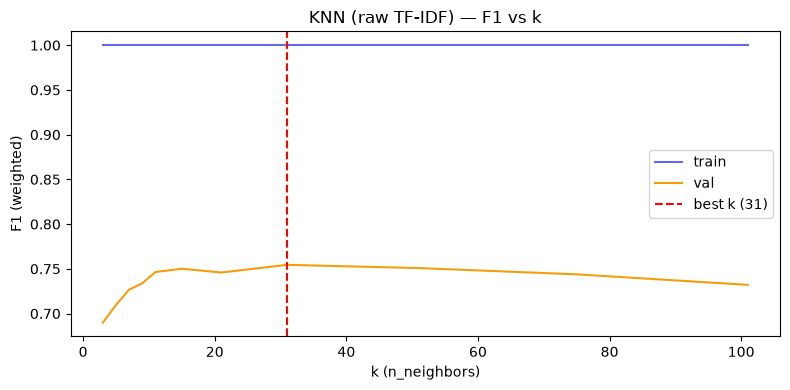

In [17]:
# ── pick whichever representation actually generalizes best (by VAL F1, test stays held out) ──
if val_metrics_svd["f1_weighted"] > val_metrics_cv["f1_weighted"]:
    space_name, space_params = "SVD", svd_grid_search.best_params_
    Xtr, Xva, Xte = X_train_svd, X_val_svd, X_test_svd
else:
    space_name, space_params = "raw TF-IDF", grid_search.best_params_
    Xtr, Xva, Xte = X_train, X_val, X_test

k_values = [3, 5, 7, 9, 11, 15, 21, 31, 51, 75, 101]
k_sweep = []
for k in k_values:
    m = KNeighborsClassifier(
        n_neighbors=k, weights=space_params["weights"], metric=space_params["metric"], n_jobs=-1,
    )
    m.fit(Xtr, y_train)
    val_f1 = f1_score(y_val, m.predict(Xva), average="weighted")
    train_f1 = f1_score(y_train, m.predict(Xtr), average="weighted")
    k_sweep.append({"k": k, "train_f1": train_f1, "val_f1": val_f1})
    print(f"k={k:>4} | train_f1={train_f1:.4f} | val_f1={val_f1:.4f}")

k_sweep_df = pd.DataFrame(k_sweep)
best_k_row = k_sweep_df.loc[k_sweep_df["val_f1"].idxmax()]
print(f"\nBest k on this sweep: {int(best_k_row['k'])} (val_f1={best_k_row['val_f1']:.4f}), "
      f"on {space_name} features with weights={space_params['weights']}, metric={space_params['metric']}")

plt.figure(figsize=(8, 4))
plt.plot(k_sweep_df["k"], k_sweep_df["train_f1"], label="train", color="#6366f1")
plt.plot(k_sweep_df["k"], k_sweep_df["val_f1"], label="val", color="#f59e0b")
plt.axvline(best_k_row["k"], color="red", linestyle="--", label=f"best k ({int(best_k_row['k'])})")
plt.xlabel("k (n_neighbors)"); plt.ylabel("F1 (weighted)")
plt.title(f"{MODEL_NAME} ({space_name}) — F1 vs k")
plt.legend(); plt.tight_layout()
plt.savefig(f"{RESULTS_DIR}/training_curve_{MODEL_NAME.lower()}.png", dpi=120, bbox_inches="tight")
plt.show()

In [18]:
final_variant = f"{space_name.replace(' ', '_')}_k{int(best_k_row['k'])}"
final_model = KNeighborsClassifier(
    n_neighbors=int(best_k_row["k"]), weights=space_params["weights"],
    metric=space_params["metric"], n_jobs=-1,
)
final_model.fit(Xtr, y_train)
print(f"Final chosen model: {MODEL_NAME} ({final_variant})")

Final chosen model: KNN (raw_TF-IDF_k31)


## Evaluate the best model on the held-out test set

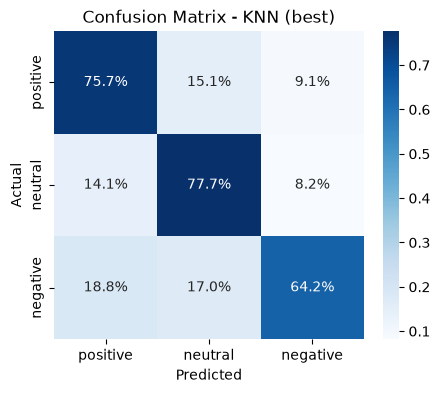

2026/07/19 16:12:29 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.



KNN (raw_TF-IDF_k31) — TEST RESULTS
              precision    recall  f1-score   support

    positive       0.72      0.76      0.74       503
     neutral       0.73      0.78      0.75       511
    negative       0.75      0.64      0.69       405

    accuracy                           0.73      1419
   macro avg       0.73      0.73      0.73      1419
weighted avg       0.73      0.73      0.73      1419



In [19]:
test_preds = final_model.predict(Xte)
test_metrics = evaluate(y_test, test_preds)

with mlflow.start_run(run_name=f"{MODEL_NAME}_BEST_{final_variant}"):
    mlflow.log_params({"variant": final_variant, **space_params, "space": space_name})
    mlflow.log_param("tfidf_max_features", TFIDF_MAX_FEATURES)
    mlflow.log_param("tfidf_ngram_range", str(TFIDF_NGRAM_RANGE))
    if space_name == "SVD":
        mlflow.log_param("svd_components", SVD_COMPONENTS)
    mlflow.log_metrics(test_metrics)
    mlflow.log_metric("search_time_seconds", round(search_time + svd_search_time, 2))

    cm_path = plot_confusion_matrix(y_test, test_preds, f"{MODEL_NAME} (best)")
    mlflow.log_artifact(cm_path)
    mlflow.sklearn.log_model(final_model, "model", skops_trusted_types=['scipy.sparse._csr.csr_matrix'])
    run_id = mlflow.active_run().info.run_id

print(f"\n{MODEL_NAME} ({final_variant}) — TEST RESULTS")
print(classification_report(y_test, test_preds, target_names=["positive", "neutral", "negative"]))

with open(f"{MODELS_DIR}/{MODEL_NAME.lower()}_best.pkl", "wb") as f:
    pickle.dump({"vectorizer": vectorizer, "svd": svd if space_name == "SVD" else None,
                 "model": final_model, "variant": final_variant}, f)

## Register the best model in the MLflow Model Registry

In [20]:
client = MlflowClient()
try:
    registered = mlflow.register_model(model_uri=f"runs:/{run_id}/model", name=f"{MODEL_NAME}_Classifier")
    print(f"Registered '{MODEL_NAME}_Classifier' version {registered.version}")
except Exception as e:
    print(f"Registration skipped/failed: {e}")

print(f"\nBest {MODEL_NAME} test F1 (weighted): {test_metrics['f1_weighted']:.4f}")

Registered model 'KNN_Classifier' already exists. Creating a new version of this model...
2026/07/19 16:12:36 WARNING mlflow.tracking._model_registry.fluent: Run with id 4d04e7435c8d49079f24adc2e552074a has no artifacts at artifact path 'model', registering model based on models:/m-79c917775552441baf63305fcf6c1348 instead


Registered 'KNN_Classifier' version 5

Best KNN test F1 (weighted): 0.7304


Created version '5' of model 'KNN_Classifier'.
